In [45]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [46]:
df = sns.load_dataset('mpg')
df


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [47]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [48]:
df = df.dropna()

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model_year    392 non-null    int64  
 7   origin        392 non-null    object 
 8   name          392 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 30.6+ KB


In [50]:
df['mpg'].describe() #46 is outlier

count    392.000000
mean      23.445918
std        7.805007
min        9.000000
25%       17.000000
50%       22.750000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64

<Axes: xlabel='mpg', ylabel='Count'>

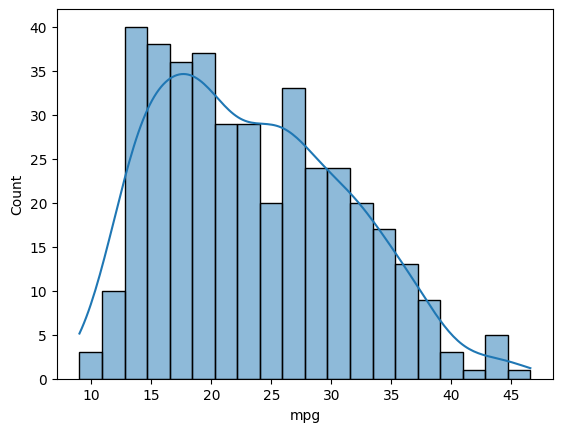

In [51]:
sns.histplot(df["mpg"], bins=20, kde=True)

In [52]:
Q1 = df['mpg'].quantile(0.25)
Q3 = df['mpg'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['mpg'] < lower_bound) | (df['mpg'] > upper_bound)]


# drop outliers
df = df.drop(outliers.index)

In [53]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [54]:
df.drop("origin", axis=1, inplace=True)
df.drop("name", axis=1, inplace=True)


In [55]:
numeric_feature = df.select_dtypes(include=['float64', 'int64']).columns
numeric_feature

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model_year'],
      dtype='object')

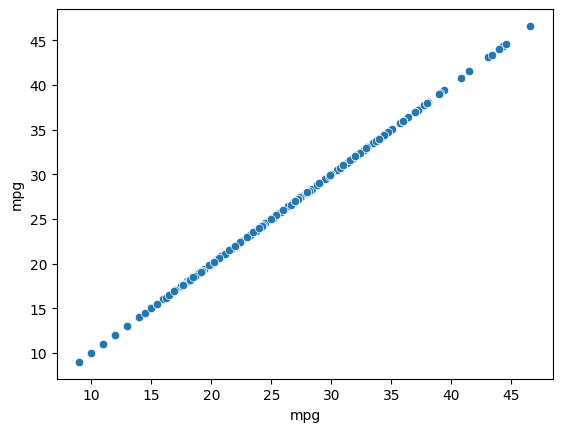

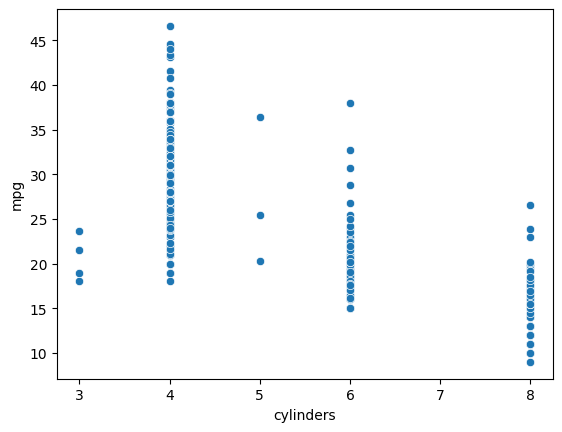

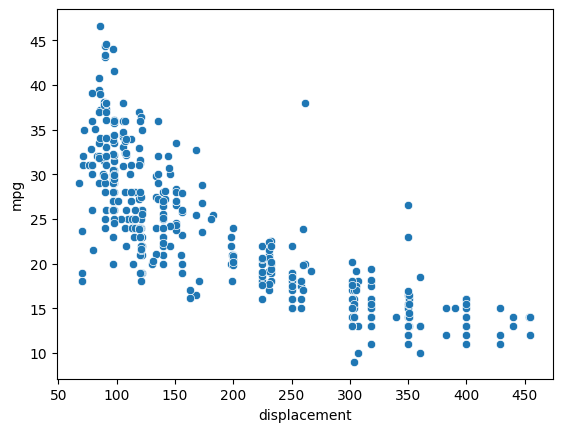

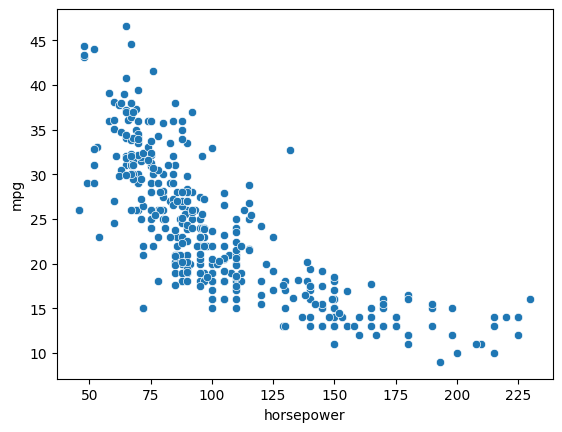

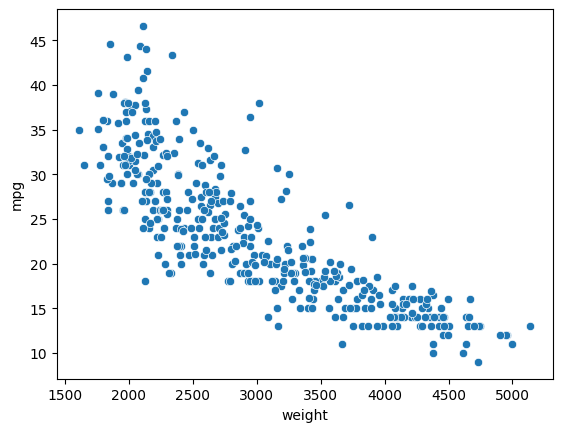

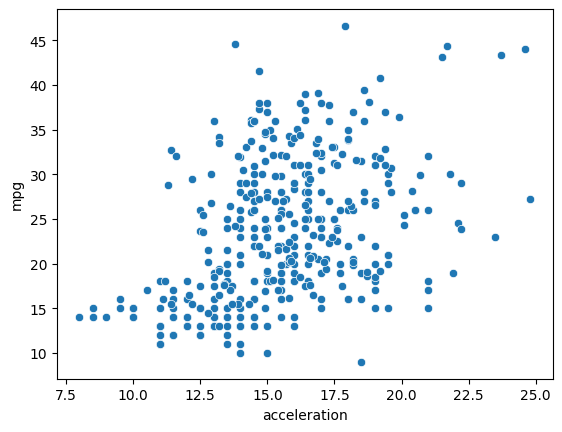

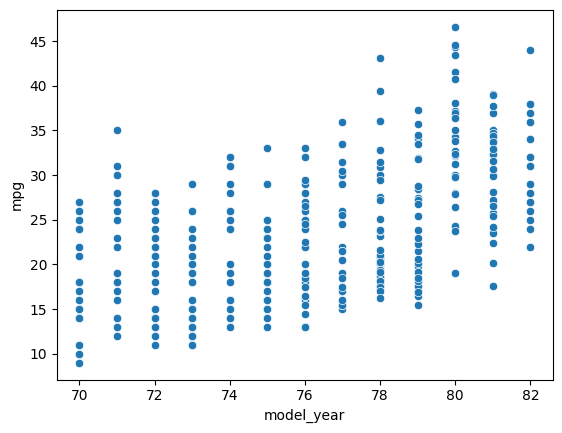

In [56]:
import matplotlib.pyplot as plt

for feature in numeric_feature:
    sns.scatterplot(x=feature, y="mpg", data=df)
    plt.show()

In [57]:
corr_matrix = df.corr(numeric_only=True)["mpg"].sort_values(ascending=False)
corr_matrix


mpg             1.000000
model_year      0.580541
acceleration    0.423329
cylinders      -0.777618
horsepower     -0.778427
displacement   -0.805127
weight         -0.832244
Name: mpg, dtype: float64

In [58]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

X = df.drop("mpg", axis=1)
y = df["mpg"]
X_train , X_test,y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [59]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (313, 6)
X_test shape: (79, 6)
y_train shape: (313,)
y_test shape: (79,)


In [60]:
X_train

,cylinders,displacement,horsepower,weight,acceleration,model_year
260,6,225.0,110.0,3620,18.7,78
184,4,140.0,92.0,2572,14.9,76
174,6,171.0,97.0,2984,14.5,75
64,8,318.0,150.0,4135,13.5,72
344,4,86.0,64.0,1875,16.4,81
...,...,...,...,...,...,...
72,8,304.0,150.0,3892,12.5,72
107,6,232.0,100.0,2789,15.0,73
272,4,151.0,85.0,2855,17.6,78
352,4,98.0,65.0,2380,20.7,81


In [61]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
numeric_transfomer = Pipeline(
    steps=[('scaler', StandardScaler())
])

# remove tip from numeric_feature
numeric_feature = numeric_feature.drop("mpg", "acceleration")
preprocesser = ColumnTransformer(
    transformers=[
        ('num', numeric_transfomer, numeric_feature)
    ]
)

In [62]:
preprocesser.fit(X_train)
X_train_preprocessed = preprocesser.transform(X_train)
X_test_preprocessed = preprocesser.transform(X_test)


In [63]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

linear_model = LinearRegression()
linear_model.fit(X_train_preprocessed, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [64]:
y_train_pred = linear_model.predict(X_train_preprocessed)

y_test_pred = linear_model.predict(X_test_preprocessed)

In [65]:
def evaluate_model(typeData,y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)*100

    return {"Type":typeData,"mse":mse, "mae":mae, "r2":r2}

In [66]:
evaluate_model("Train",y_train, y_train_pred)

{'Type': 'Train',
 'mse': 11.943343161136761,
 'mae': 2.669175930481722,
 'r2': 81.07227953093896}

In [67]:
evaluate_model("Test",y_test, y_test_pred)

{'Type': 'Test',
 'mse': 10.502370329417294,
 'mae': 2.5038600897761234,
 'r2': 79.42349075428592}